In [37]:
import numpy as np
L=np.array([1,0])
R=np.array([0,1])
B=L
T=R
epsilon=10.0
nu=0.0
gamma=5.0
dgamma=0.5
dt=0.11
sigma_z=np.outer(L,L)-np.outer(R,R)
sigma_x=np.outer(L,R)+np.outer(R,L)
H_q=epsilon*sigma_z+nu*sigma_x
H_e=gamma*sigma_x
H_k=-dgamma*(np.kron(np.outer(R,R),sigma_x))
I=np.eye(2)
H=np.kron(H_q,I)+np.kron(I,H_e)+H_k


In [41]:
from scipy.linalg import expm
rh=6.582119569 #reduced Planck's constant in eV*s*10^-16
units=10 #Energy in eV*10^-6 time in s*10^-9, so all in all eV*s*10^-15/ev*s*10^-16 = 10
U = expm(-1j * H * dt * units / rh)
print(np.allclose(U.conj().T @ U, np.eye(4))) #Checking whether U is unitary

True


In [44]:
#Starting state: |LB>
psi_0=np.array([1,0,0,0])
#state after dt time evolution:
psi_1=np.dot(U,psi_0)
P=np.kron(I,np.outer(T,T))
print(psi_1)
print(np.dot(P,psi_1))
print(np.conjugate(psi_1).T)
p1= np.real(np.vdot(psi_1, P @ psi_1))
print(p1)

[-0.06722728-0.66735736j -0.73796222+0.07433978j  0.        +0.j
  0.        +0.j        ]
[ 0.        +0.j         -0.73796222+0.07433978j  0.        +0.j
  0.        +0.j        ]
[-0.06722728+0.66735736j -0.73796222-0.07433978j  0.        -0.j
  0.        -0.j        ]
0.5501146435313815


In [45]:
#Starting state: |RB>
psi_0=np.array([0,0,1,0])
#state after dt time evolution:
psi_1=np.dot(U,psi_0)
P=np.kron(I,np.outer(T,T))
print(psi_1)
print(np.dot(P,psi_1))
print(np.conjugate(psi_1).T)
p2= np.real(np.vdot(psi_1, P @ psi_1))
print(p2)

[ 0.        +0.j          0.        +0.j         -0.07319731+0.72662107j
  0.67968809+0.06846944j]
[0.        +0.j         0.        +0.j         0.        +0.j
 0.67968809+0.06846944j]
[ 0.        -0.j          0.        -0.j         -0.07319731-0.72662107j
  0.67968809-0.06846944j]
0.4666639702449979


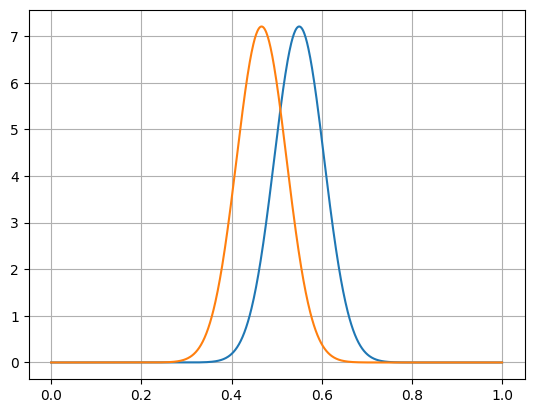

In [59]:
import matplotlib.pyplot as plt
N=20
sample_stand_dev1=p1*(1-p1)/np.sqrt(N)
f=lambda x,p: np.e**(-0.5*((x-p)/sample_stand_dev1)**2)*1/(sample_stand_dev1*np.sqrt(2*np.pi))
xarr=np.linspace(0,1,1000)
yarr1=f(xarr,p1)
yarr2=f(xarr,p2)
plt.plot(xarr,yarr1)
plt.plot(xarr,yarr2)
plt.grid()
plt.show()